# Red Wine Quality: Reproducible Data Workflow

**Author:** Megern Qaisse  
**Dataset:** UCI Wine Quality - Red Vinho Verde  

This project develops a reproducible workflow for exploring how physicochemical measurements relate to red wine quality. It demonstrates data ingestion, documented cleaning, exploratory analysis, and visual communication using Python.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid')
print('Libraries imported successfully.')

Libraries imported successfully.


## 2. Data Ingestion

In [2]:
df = pd.read_csv('winequality-red.csv', sep=';')
print(f'Raw dataset shape: {df.shape}')
df.head()

Raw dataset shape: (1599, 12)

 fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  free sulfur dioxide  total sulfur dioxide  density   pH  sulphates  alcohol  quality
           7.4              0.70         0.00             1.9      0.076                 11.0                  34.0   0.9978 3.51       0.56      9.4        5
           7.8              0.88         0.00             2.6      0.098                 25.0                  67.0   0.9968 3.20       0.68      9.8        5
           7.8              0.76         0.04             2.3      0.092                 15.0                  54.0   0.9970 3.26       0.65      9.8        5
          11.2              0.28         0.56             1.9      0.075                 17.0                  60.0   0.9980 3.16       0.58      9.8        6
           7.4              0.70         0.00             1.9      0.076                 11.0                  34.0   0.9978 3.51       0.56      9.4        5


In [3]:
print(df.info())
print('Missing values by column:')
print(df.isna().sum())
print(f'Exact duplicate rows: {df.duplicated().sum()}')

Rows: 1599, Columns: 12
All columns are numeric.
Missing values by column:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Exact duplicate rows: 240


## 3. Data Cleaning

Column names are standardized so later code has a consistent interface. Exact duplicate observations are removed because counting the same measured wine twice would overweight its chemistry in summary statistics and plots. The source contains no missing values, so imputation is not necessary.

In [4]:
def standardize_columns(frame):
    """Return a copy with lowercase, underscore-separated column names."""
    cleaned = frame.copy()
    cleaned.columns = cleaned.columns.str.strip().str.lower().str.replace(' ', '_')
    return cleaned

def remove_duplicate_rows(frame):
    """Remove exact duplicate observations and reset the row index."""
    return frame.drop_duplicates().reset_index(drop=True)

In [5]:
df_clean = standardize_columns(df)
df_clean = remove_duplicate_rows(df_clean)
print(f'Rows before cleaning: {len(df):,}')
print(f'Rows after cleaning:  {len(df_clean):,}')
print(f'Duplicates removed:   {len(df) - len(df_clean):,}')

Rows before cleaning: 1,599
Rows after cleaning:  1,359
Duplicates removed:   240


## 4. Exploratory Data Analysis

In [6]:
def exploratory_summary(frame):
    """Compute descriptive statistics, grouped quality values, and correlations."""
    numeric_summary = frame.describe().T[['mean', 'std', 'min', 'max']].round(3)
    quality_summary = frame.groupby('quality')['alcohol'].agg(['count', 'mean', 'median']).round(3)
    quality_correlations = frame.corr(numeric_only=True)['quality'].sort_values()
    return numeric_summary, quality_summary, quality_correlations

summary_stats, quality_alcohol, quality_corr = exploratory_summary(df_clean)
print(summary_stats)
print('\nAlcohol grouped by quality:')
print(quality_alcohol)
print('\nCorrelations with quality:')
print(quality_corr)

Descriptive statistics:
                        mean     std    min      max
fixed_acidity          8.311   1.737  4.600   15.900
volatile_acidity       0.529   0.183  0.120    1.580
citric_acid            0.272   0.196  0.000    1.000
residual_sugar         2.523   1.352  0.900   15.500
chlorides              0.088   0.049  0.012    0.611
free_sulfur_dioxide   15.893  10.447  1.000   72.000
total_sulfur_dioxide  46.826  33.409  6.000  289.000
density                0.997   0.002  0.990    1.004
ph                     3.310   0.155  2.740    4.010
sulphates              0.659   0.171  0.330    2.000
alcohol               10.432   1.082  8.400   14.900
quality                5.623   0.824  3.000    8.000

Alcohol grouped by quality:
         count    mean  median
quality                       
3           10   9.955   9.925
4           53  10.265  10.000
5          577   9.889   9.600
6          535  10.659  10.500
7          167  11.491  11.600
8           17  12.159  12.500

Correlati

## 5. Visualizations

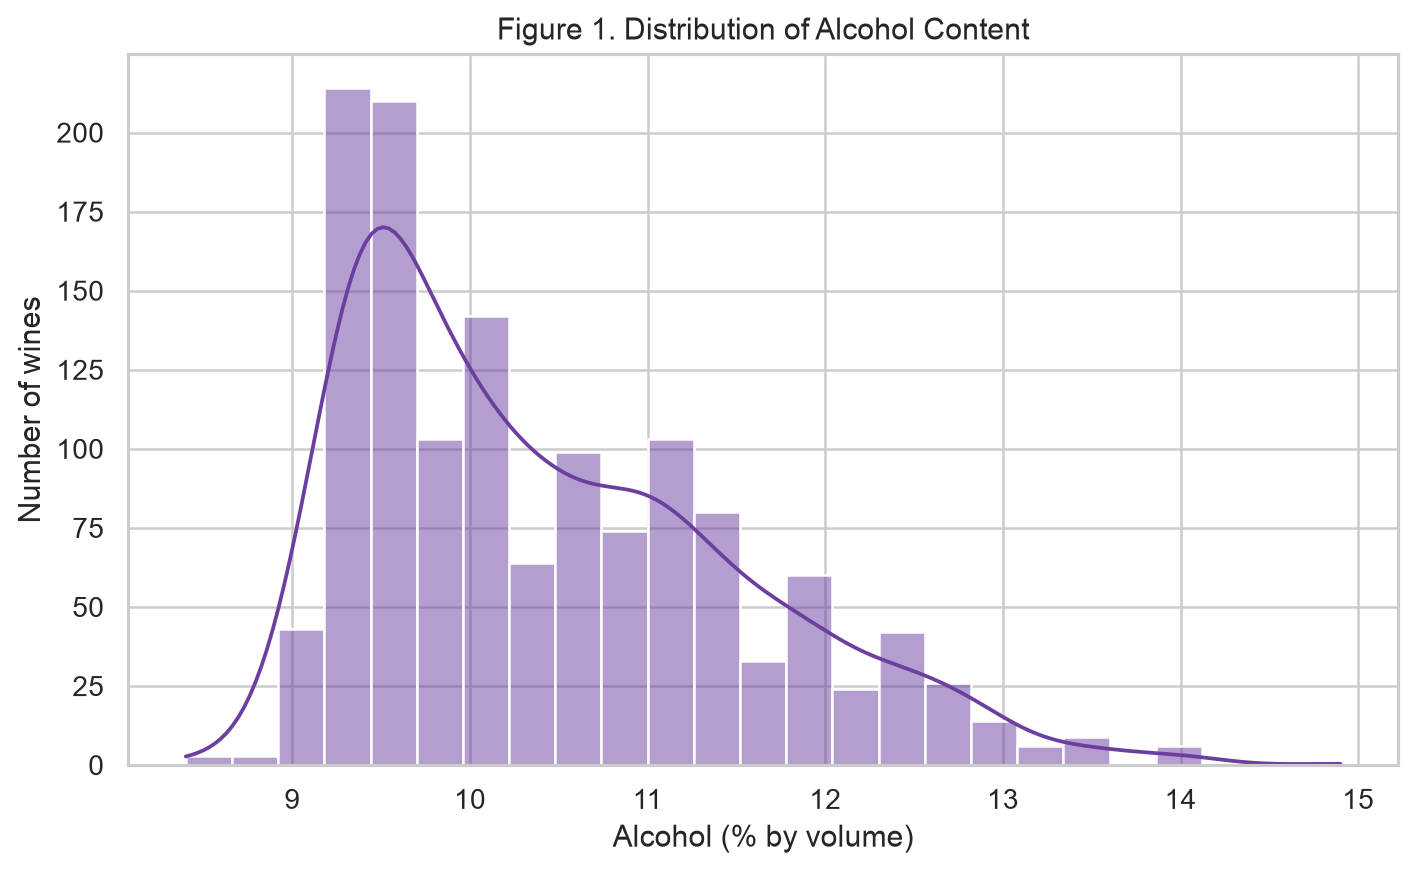

In [7]:
sns.histplot(df_clean['alcohol'], bins=25, kde=True, color='#6b3fa0')
plt.title('Figure 1. Distribution of Alcohol Content')
plt.xlabel('Alcohol (% by volume)'); plt.ylabel('Number of wines'); plt.show()

Interpretation: alcohol is concentrated around the middle of the observed range, with fewer very low or very high values.

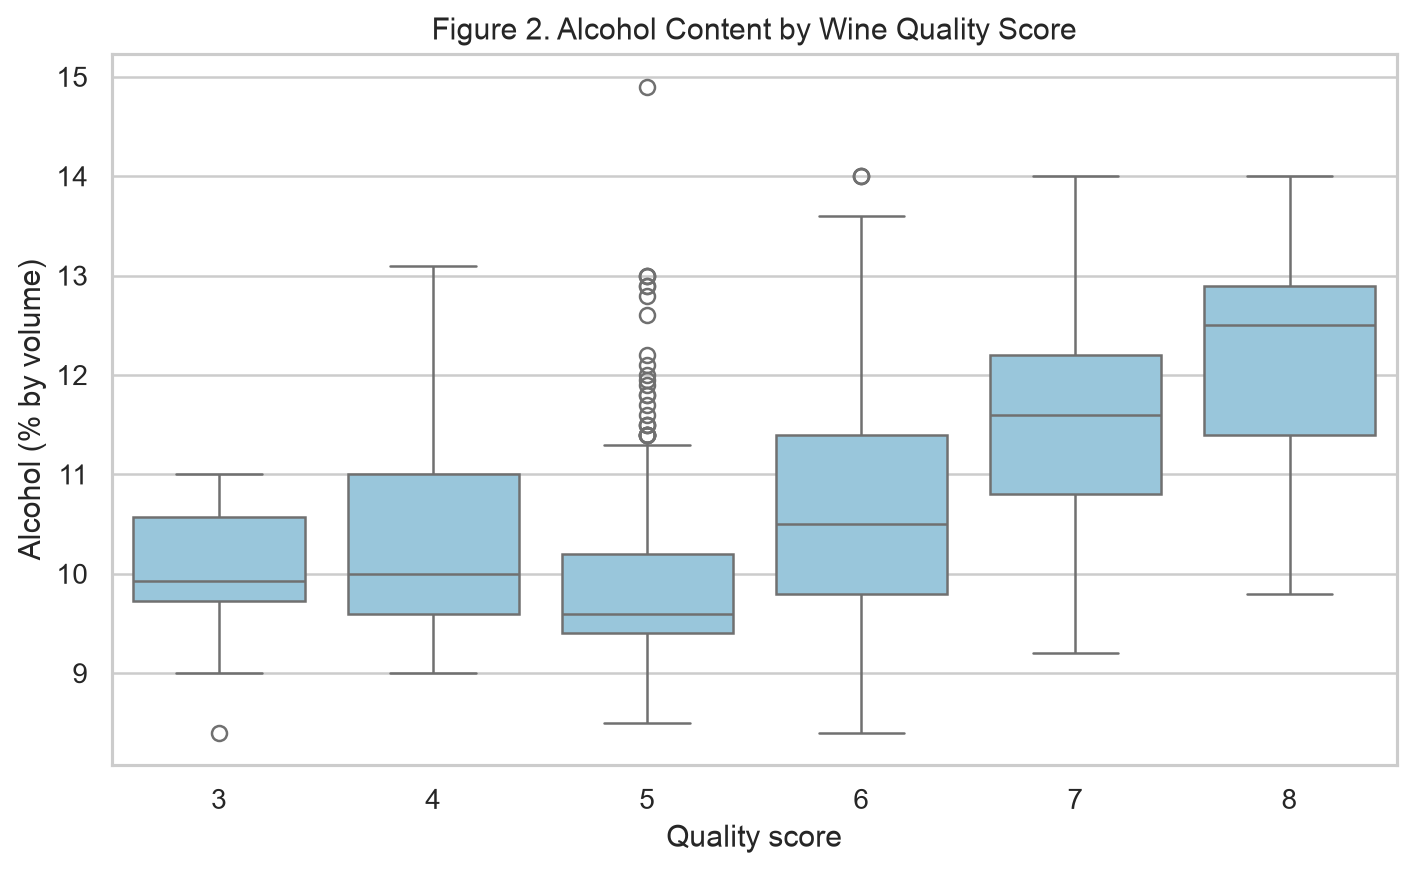

In [8]:
sns.boxplot(data=df_clean, x='quality', y='alcohol', color='#8ecae6')
plt.title('Figure 2. Alcohol Content by Wine Quality Score')
plt.xlabel('Quality score'); plt.ylabel('Alcohol (% by volume)'); plt.show()

Interpretation: median alcohol content generally increases for higher quality scores, although the groups overlap.

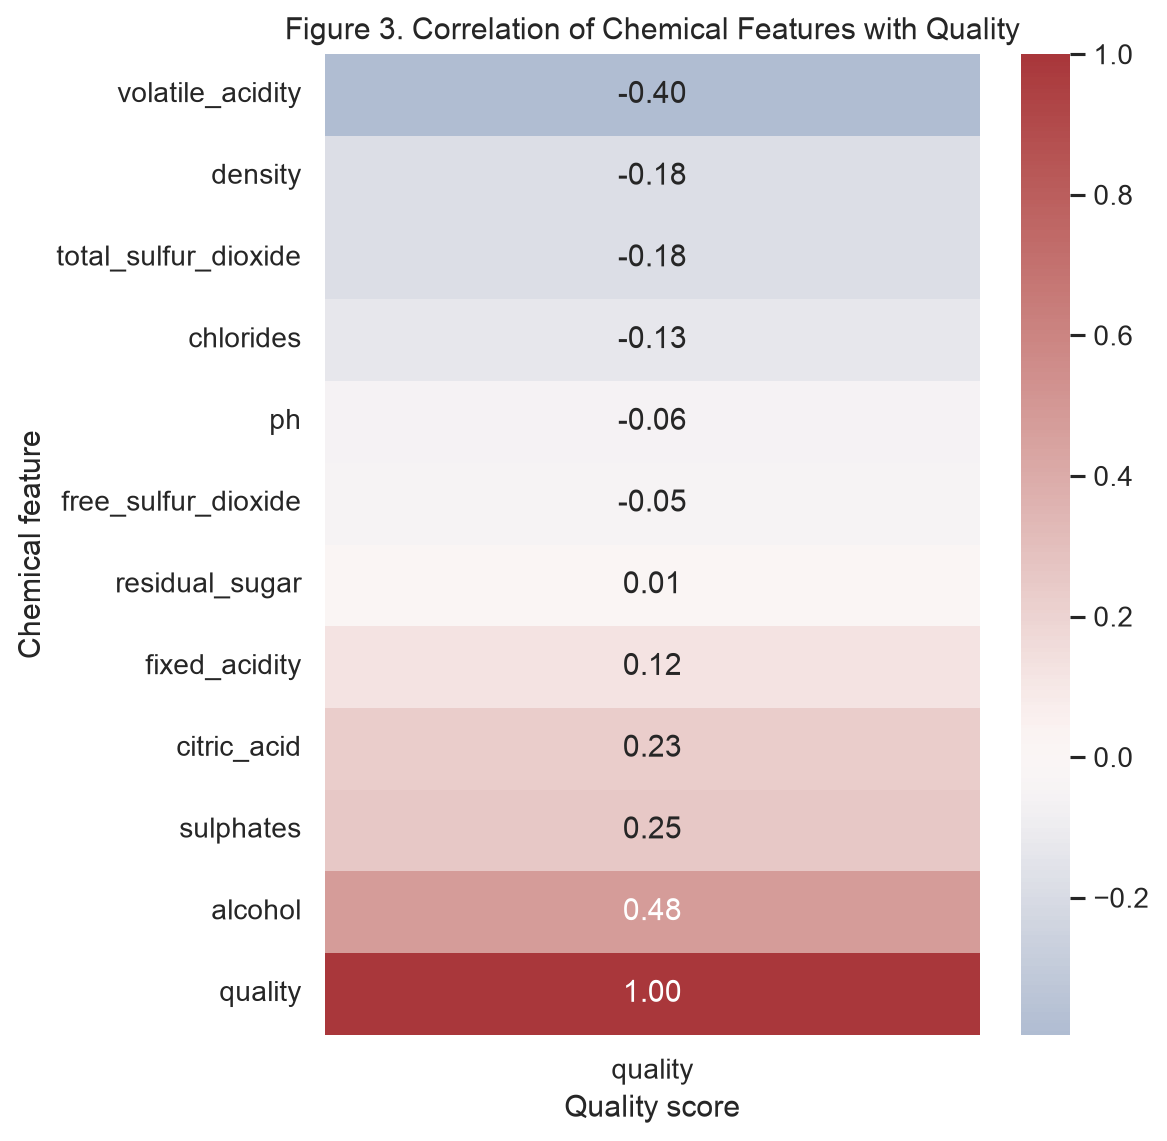

In [9]:
quality_correlations = df_clean.corr(numeric_only=True)[['quality']].sort_values('quality')
sns.heatmap(quality_correlations, annot=True, fmt='.2f', cmap='vlag', center=0)
plt.title('Figure 3. Correlation of Chemical Features with Quality')
plt.xlabel('Quality score'); plt.ylabel('Chemical feature'); plt.show()

Interpretation: alcohol has a positive association with quality, while volatile acidity has one of the strongest negative associations.

## 6. Summary and Interpretation

The cleaned data contains a broad set of wine chemistry measurements and an ordinal quality score. Higher-quality wines tend to have higher alcohol content, whereas volatile acidity is negatively associated with quality. These are descriptive relationships rather than causal effects: the data does not identify wine brand, grapes, production conditions, price, or the judges' full context. Removing duplicates improves the representation of observed samples, but it cannot make this convenience dataset representative of all red wines.